In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize

In [2]:
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df.head()

,date,new_cases,cases_7d,I
0,2020-02-05,1.0,3.000000,21.0
1,2020-02-06,0.0,2.857143,20.0
2,2020-02-07,0.0,2.857143,20.0
3,2020-02-08,3.0,3.285714,23.0
4,2020-02-09,1.0,3.285714,23.0


In [3]:
df_sir = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_sir = df_sir.reset_index(drop=True)

print(df_sir.shape)
df_sir.head()

(63, 4)


,date,new_cases,cases_7d,I
0,2021-12-01,47263.0,39422.714286,275959.0
1,2021-12-02,43045.0,40265.857143,281861.0
2,2021-12-03,39222.0,41059.571429,287417.0
3,2021-12-04,33380.0,41762.571429,292338.0
4,2021-12-05,35037.0,41931.142857,293518.0


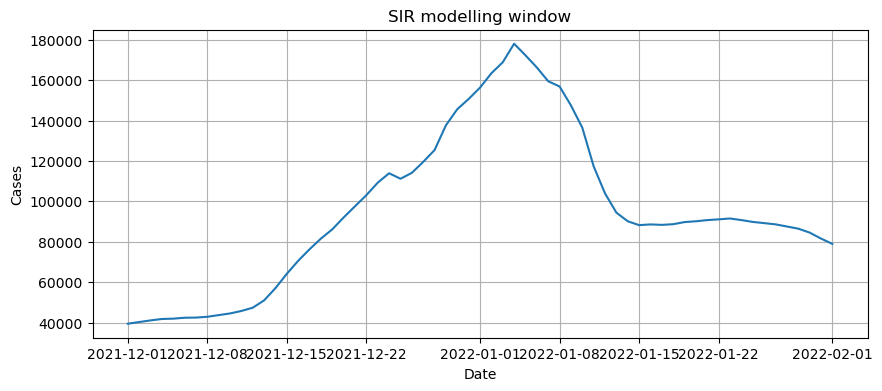

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(df_sir["date"], df_sir["cases_7d"])
plt.title("SIR modelling window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.grid()
plt.show()

In [5]:
I_data = df_sir["cases_7d"].values
t_data = np.arange(len(df_sir))

print("Number of time points:", len(t_data))
print("Initial infected value:", I_data[0])

Number of time points: 63
Initial infected value: 39422.71428571428


In [6]:
N = 56_000_000

I0 = float(I_data[0])
R0 = 0.0
S0 = N - I0 - R0

print("S0 =", S0)
print("I0 =", I0)
print("R0 =", R0)

S0 = 55960577.28571428
I0 = 39422.71428571428
R0 = 0.0


In [7]:
def sir_model(t, y, beta, gamma, N):
    S, I, R = y
    
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    
    return [dSdt, dIdt, dRdt]

In [8]:
def simulate_sir(beta, gamma, N, S0, I0, R0, t_eval):
    y0 = [S0, I0, R0]
    
    sol = solve_ivp(
        fun=lambda t, y: sir_model(t, y, beta, gamma, N),
        t_span=(t_eval[0], t_eval[-1]),
        y0=y0,
        t_eval=t_eval,
        method="RK45"
    )
    
    return sol.y

In [9]:
def loss_fn(params):
    beta, gamma = params
    
    if beta <= 0 or gamma <= 0:
        return 1e20
    
    S, I, R = simulate_sir(beta, gamma, N, S0, I0, R0, t_data)
    
    return np.mean((I - I_data) ** 2)

In [10]:
initial_guess = [0.4, 1/7]

result = minimize(
    loss_fn,
    x0=initial_guess,
    bounds=[(1e-4, 2.0), (1e-4, 1.0)],
    method="L-BFGS-B"
)

beta_hat, gamma_hat = result.x

print("Estimated beta:", beta_hat)
print("Estimated gamma:", gamma_hat)
print("Estimated R0:", beta_hat / gamma_hat)
print("Loss:", result.fun)

Estimated beta: 1.04198607530067
Estimated gamma: 0.9802675180607728
Estimated R0: 1.0629609327074232
Loss: 337251633.66526145


In [11]:
S_fit, I_fit, R_fit = simulate_sir(beta_hat, gamma_hat, N, S0, I0, R0, t_data)

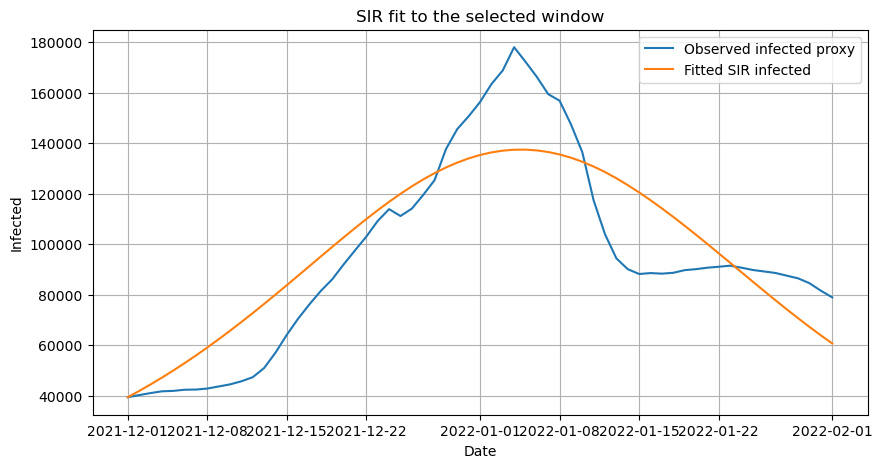

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], I_data, label="Observed infected proxy")
plt.plot(df_sir["date"], I_fit, label="Fitted SIR infected")
plt.title("SIR fit to the selected window")
plt.xlabel("Date")
plt.ylabel("Infected")
plt.legend()
plt.grid()
plt.show()

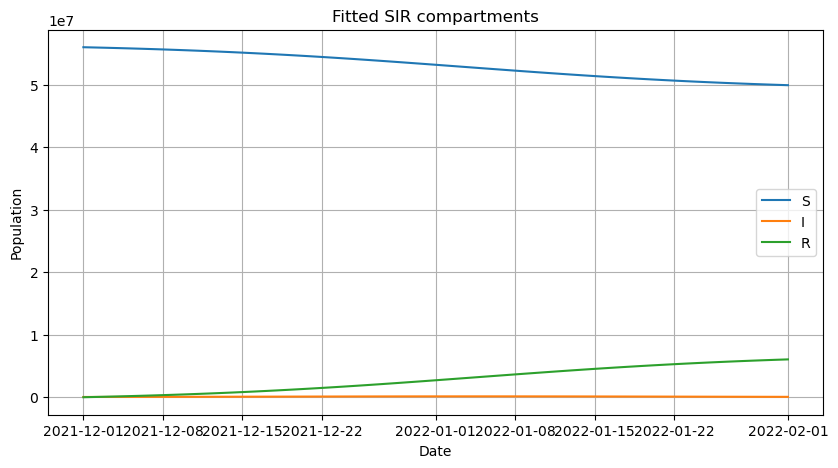

In [13]:
plt.figure(figsize=(10, 5))
plt.plot(df_sir["date"], S_fit, label="S")
plt.plot(df_sir["date"], I_fit, label="I")
plt.plot(df_sir["date"], R_fit, label="R")
plt.title("Fitted SIR compartments")
plt.xlabel("Date")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()